# IBM Default Probability: Merton, KMV-Style Iteration and the Naive Model

How far is IBM from default, and how does the answer depend on the model? The notebook estimates IBM's one-year distance to default (DD) and default probability (PD) at each month-end of the last year from market data:

1. **Merton (1974) with the KMV iterative procedure:** treat equity as a call on the firm's assets with strike equal to the default point, and iterate until the asset volatility implied by the daily asset values matches the one used to back them out.
2. **Merton with drift:** the same assets, but the real-world PD uses the estimated asset drift μ instead of the risk-free rate.
3. **Naive model (Bharath and Shumway, 2008):** no equation solving; asset volatility is approximated from equity volatility and a debt-volatility rule of thumb.

Each estimate uses only the 252 trading days up to its date. Asset values are priced with the risk-free rate; the drift enters only the real-world DD.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import brentq
from scipy.stats import norm

sns.set_theme(style="whitegrid")
T = 1.0              # horizon, years
WINDOW = 252         # trading days per estimation window

## Data

From Yahoo Finance: IBM daily closes and shares outstanding, IBM's quarterly balance sheets (current and long-term debt), and the 13-week Treasury bill yield (`^IRX`) as the risk-free rate. The first run downloads them; the snapshot in `data/` keeps later runs identical.

In [2]:
DATA = Path("data")
files = {name: DATA / f"{name}.csv" for name in ["prices", "debt", "rates"]}
if not all(f.exists() for f in files.values()):
    import yfinance as yf
    DATA.mkdir(exist_ok=True)
    ibm = yf.Ticker("IBM")
    hist = ibm.history(period="3y", auto_adjust=False)[["Close"]]
    hist.index = hist.index.tz_localize(None).normalize()
    shares = ibm.get_shares_full(start=hist.index[0])
    shares.index = shares.index.tz_localize(None).normalize()
    shares = shares.groupby(level=0).last()
    hist["shares"] = shares.reindex(hist.index, method="ffill").bfill()
    hist.to_csv(files["prices"])

    sheets = pd.concat([ibm.quarterly_balance_sheet, ibm.balance_sheet], axis=1)
    sheets = sheets.loc[:, ~sheets.columns.duplicated()]
    def row(*names):
        for n in names:
            if n in sheets.index:
                return sheets.loc[n]
        raise KeyError(names)
    debt = pd.DataFrame({
        "current_debt": row("Current Debt", "Current Debt And Capital Lease Obligation"),
        "long_term_debt": row("Long Term Debt", "Long Term Debt And Capital Lease Obligation"),
    }).sort_index().dropna()
    debt.to_csv(files["debt"])

    irx = yf.Ticker("^IRX").history(period="3y")[["Close"]].rename(columns={"Close": "rate_pct"})
    irx.index = irx.index.tz_localize(None).normalize()
    irx.to_csv(files["rates"])

prices = pd.read_csv(files["prices"], index_col=0, parse_dates=True)
debt = pd.read_csv(files["debt"], index_col=0, parse_dates=True)
rates = pd.read_csv(files["rates"], index_col=0, parse_dates=True)
debt

,current_debt,long_term_debt
2022-12-31,4.760000e+09,4.618900e+10
2023-12-31,6.426000e+09,5.012100e+10
2024-12-31,5.089000e+09,4.988400e+10
2025-06-30,8.945000e+09,5.521900e+10
2025-09-30,7.942000e+09,5.517400e+10
2025-12-31,6.424000e+09,5.483600e+10
2026-03-31,8.655000e+09,5.770600e+10
2026-06-30,5.775000e+09,5.621200e+10


The **default point** is the KMV convention: short-term debt plus half of long-term debt, in dollars. Each balance sheet applies from its date until the next one; days before the earliest available sheet use that sheet.

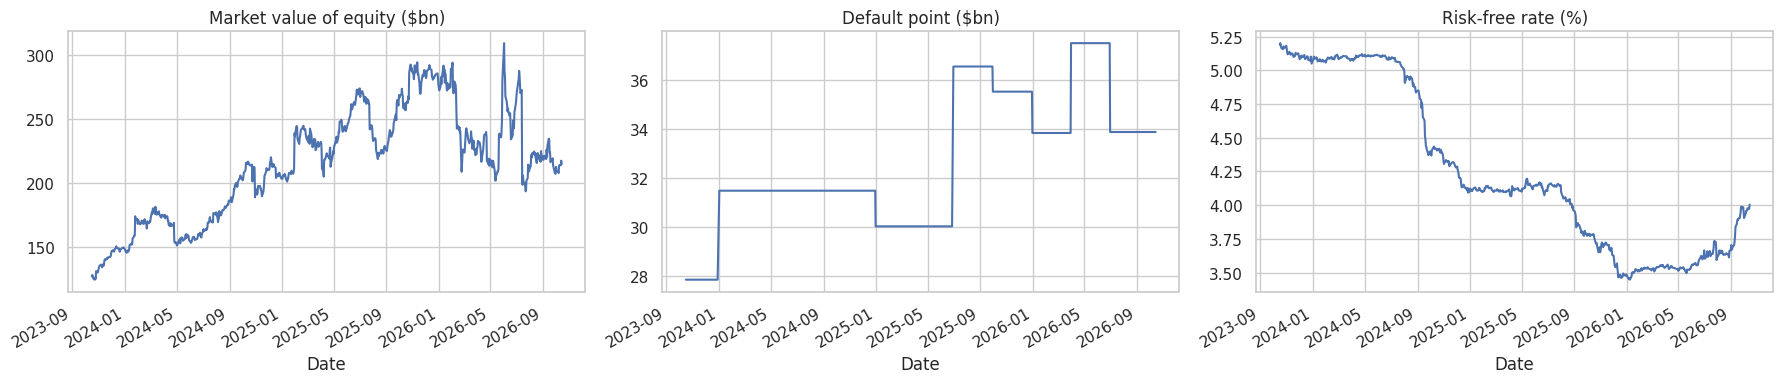

,count,mean,std,min,25%,50%,75%,max
E,752.0,2.140518e+11,4.301880e+10,1.242430e+11,1.757584e+11,2.169540e+11,2.419799e+11,3.094384e+11
F,752.0,3.269609e+10,2.721795e+09,2.785450e+10,3.148650e+10,3.148650e+10,3.552900e+10,3.750800e+10
r,752.0,4.248215e-02,6.015698e-03,3.446906e-02,3.664047e-02,4.121872e-02,5.062657e-02,5.202303e-02


In [3]:
df = prices.join(rates, how="inner")
df["E"] = df["Close"] * df["shares"]
df["r"] = np.log1p(df["rate_pct"] / 100)          # continuously compounded
default_point = debt["current_debt"] + 0.5 * debt["long_term_debt"]
df["F"] = default_point.reindex(df.index, method="ffill").bfill()
df = df.dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
(df["E"] / 1e9).plot(ax=axes[0], title="Market value of equity ($bn)")
(df["F"] / 1e9).plot(ax=axes[1], title="Default point ($bn)")
(100 * df["r"]).plot(ax=axes[2], title="Risk-free rate (%)")
plt.tight_layout()
plt.show()
df[["E", "F", "r"]].describe().T

## The models

In [4]:
def d1_d2(V, F, r, sigma, T=T):
    d1 = (np.log(V / F) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)

def equity_value(V, F, r, sigma):
    d1, d2 = d1_d2(V, F, r, sigma)
    return V * norm.cdf(d1) - F * np.exp(-r * T) * norm.cdf(d2)

def implied_assets(E, F, r, sigma):
    """Asset value V solving E = BS call(V, F, r, sigma), day by day."""
    return np.array([brentq(lambda v: equity_value(v, f, rr, sigma) - e, e, e + 2 * f)
                     for e, f, rr in zip(E, F, r)])

def kmv(window, tol=1e-6, max_iter=100):
    """Iterate sigma_V until the volatility of the implied asset path reproduces it."""
    E, F, r = window["E"].to_numpy(), window["F"].to_numpy(), window["r"].to_numpy()
    sigma_E = np.std(np.diff(np.log(E)), ddof=1) * np.sqrt(252)
    sigma = sigma_E * E[-1] / (E[-1] + F[-1])
    for i in range(max_iter):
        V = implied_assets(E, F, r, sigma)
        new_sigma = np.std(np.diff(np.log(V)), ddof=1) * np.sqrt(252)
        if abs(new_sigma - sigma) < tol:
            break
        sigma = new_sigma
    rets = np.diff(np.log(V))
    mu = rets.mean() * 252 + 0.5 * new_sigma**2        # annual drift of assets
    return {"V": V[-1], "sigma_V": new_sigma, "mu": mu, "sigma_E": sigma_E, "iterations": i + 1}

def distance_to_default(V, F, drift, sigma):
    return (np.log(V / F) + (drift - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

def naive(window):
    """Bharath and Shumway (2008): sigma_D = 0.05 + 0.25 sigma_E, V = E + F, mu = past equity return."""
    E, F = window["E"].iloc[-1], window["F"].iloc[-1]
    sigma_E = np.std(np.diff(np.log(window["E"])), ddof=1) * np.sqrt(252)
    sigma_D = 0.05 + 0.25 * sigma_E
    sigma_V = E / (E + F) * sigma_E + F / (E + F) * sigma_D
    mu = np.log(window["E"].iloc[-1] / window["E"].iloc[0])
    return distance_to_default(E + F, F, mu, sigma_V), sigma_V

## Month-end estimates over the last year

In [5]:
month_ends = df.groupby(df.index.to_period("M")).tail(1).index
month_ends = [d for d in month_ends if df.index.get_loc(d) >= WINDOW][-12:]

rows = []
for date in month_ends:
    w = df.loc[:date].iloc[-WINDOW:]
    est = kmv(w)
    F, r = w["F"].iloc[-1], w["r"].iloc[-1]
    dd_rn = distance_to_default(est["V"], F, r, est["sigma_V"])
    dd_mu = distance_to_default(est["V"], F, est["mu"], est["sigma_V"])
    dd_naive, sigma_naive = naive(w)
    rows.append({"date": date.date(), "E ($bn)": w["E"].iloc[-1] / 1e9, "F ($bn)": F / 1e9,
                 "V ($bn)": est["V"] / 1e9, "sigma_E": est["sigma_E"], "sigma_V": est["sigma_V"],
                 "mu": est["mu"], "iterations": est["iterations"],
                 "DD risk-neutral": dd_rn, "DD with drift": dd_mu, "DD naive": dd_naive,
                 "PD risk-neutral": norm.cdf(-dd_rn), "PD with drift": norm.cdf(-dd_mu),
                 "PD naive": norm.cdf(-dd_naive), "sigma_V naive": sigma_naive})
results = pd.DataFrame(rows).set_index("date")
results.round(4)

,E ($bn),F ($bn),V ($bn),sigma_E,sigma_V,mu,iterations,DD risk-neutral,DD with drift,DD naive,PD risk-neutral,PD with drift,PD naive,sigma_V naive
date,,,,,,,,,,,,,,
2025-11-28,288.4406,35.529,322.7029,0.3043,0.2710,0.3267,2,8.1406,9.2122,8.7084,0.0,0.0000,0.0000,0.2847
2025-12-31,276.8779,33.842,309.5607,0.3001,0.2679,0.3174,2,8.2574,9.3118,8.8412,0.0,0.0000,0.0000,0.2811
2026-01-30,286.6833,33.842,319.3582,0.2923,0.2614,0.2116,2,8.5918,9.2670,8.7209,0.0,0.0000,0.0000,0.2744
2026-02-27,224.5328,33.842,257.2057,0.3444,0.3065,0.0222,2,6.5784,6.5362,6.1096,0.0,0.0000,0.0000,0.3171
2026-03-31,227.4610,37.508,263.6656,0.3442,0.3071,0.0636,2,6.3113,6.4031,6.0112,0.0,0.0000,0.0000,0.3147
2026-04-30,217.0947,37.508,253.3046,0.3392,0.3020,0.0445,2,6.2907,6.3216,5.9287,0.0,0.0000,0.0000,0.3091
2026-05-29,279.8978,37.508,316.1067,0.3791,0.3355,0.2174,2,6.2911,6.8341,6.3347,0.0,0.0000,0.0000,0.3514
2026-06-30,264.3051,33.881,296.9672,0.4084,0.3595,0.0246,2,5.9601,5.9265,5.4500,0.0,0.0000,0.0000,0.3793
2026-07-31,210.7084,33.881,243.3861,0.5044,0.4435,-0.0091,2,4.3060,4.2039,3.8325,0.0,0.0000,0.0001,0.4589


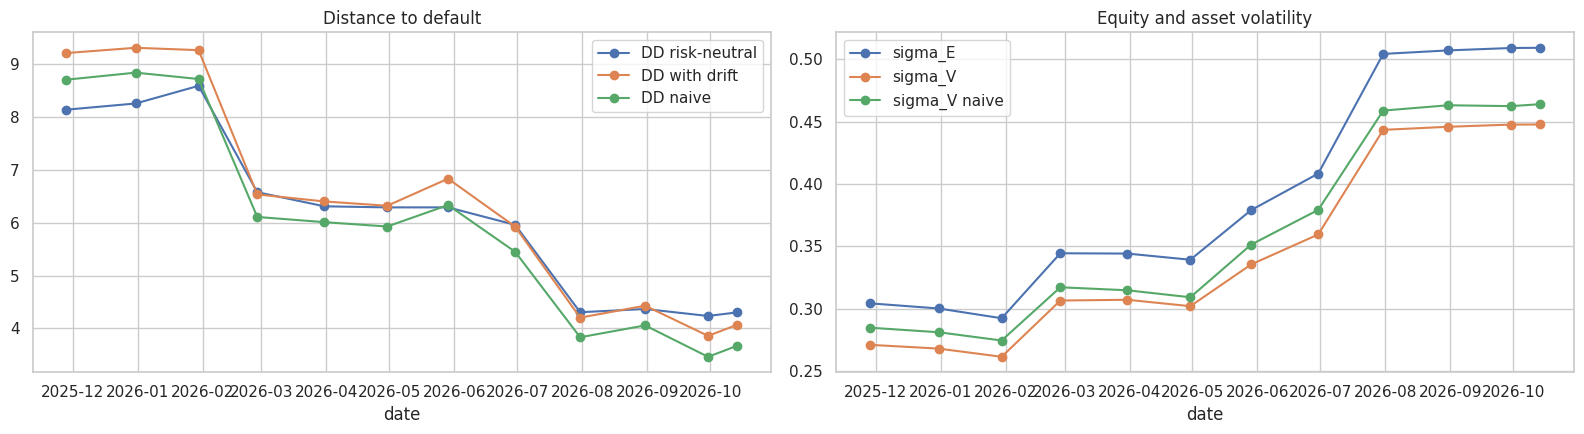

,PD risk-neutral,PD with drift,PD naive
date,,,
2025-11-28,1.97e-16,1.60e-20,1.54e-18
2025-12-31,7.45e-17,6.28e-21,4.74e-19
2026-01-30,4.28e-18,9.58e-21,1.38e-18
2026-02-27,2.38e-11,3.16e-11,4.99e-10
2026-03-31,1.38e-10,7.61e-11,9.21e-10
2026-04-30,1.58e-10,1.29e-10,1.53e-09
2026-05-29,1.58e-10,4.13e-12,1.19e-10
2026-06-30,1.26e-09,1.55e-09,2.52e-08
2026-07-31,8.31e-06,1.31e-05,6.34e-05


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
results[["DD risk-neutral", "DD with drift", "DD naive"]].plot(ax=axes[0], marker="o", title="Distance to default")
results[["sigma_E", "sigma_V", "sigma_V naive"]].plot(ax=axes[1], marker="o", title="Equity and asset volatility")
plt.tight_layout()
plt.show()
results[["PD risk-neutral", "PD with drift", "PD naive"]].map(lambda p: f"{p:.2e}")

In [7]:
# Checks: the iteration converged, assets price equity back, and V exceeds equity.
last = df.loc[:month_ends[-1]].iloc[-WINDOW:]
est = kmv(last)
assert est["iterations"] < 100
assert np.isclose(equity_value(est["V"], last["F"].iloc[-1], last["r"].iloc[-1], est["sigma_V"]), last["E"].iloc[-1], rtol=1e-6)
assert (results["V ($bn)"] > results["E ($bn)"]).all()
assert (results["sigma_V"] < results["sigma_E"]).all()

## Conclusion

- **IBM is far from default, but noticeably less so than a year ago.** The risk-neutral distance to default fell from about 8.2-8.6 standard deviations (November 2025 to January 2026) to about 4.2-4.3 (July to October 2026). Equity volatility rose from 30% to 51% while the market value of equity fell from about $287bn to $207-215bn; the default point stayed near $34-38bn.
- **Default probabilities stay tiny in absolute terms** (below 10⁻⁴ under Merton), as expected for a firm whose debt is only 12-14% of its asset value. The trend in DD is more informative than the PD level, which depends heavily on the normality assumption.
- **The KMV iteration converges in two steps** because leverage is low: asset volatility is close to equity volatility scaled by E/V.
- **The naive model is the most conservative once volatility rises.** From February 2026 its DD is the lowest of the three (3.5-3.8 against 4.2-4.3 in September-October), because its debt-volatility rule adds risk that Merton's riskless-debt assumption leaves out. Using the estimated drift instead of the risk-free rate matters only when the drift is far from r, as in September 2026, when IBM's negative trailing return lowered the DD from 4.24 to 3.86.
